# Proyek Analisis Data: E-Commerce Public Dataset (Olist)

- **Nama:** (Syahidah Azzahro)
- **Email:** (zahro39@gmail.com)
- **ID Dicoding:** (syahidahazzahro)

## Daftar Isi
1. Menentukan Pertanyaan Bisnis
2. Import Library
3. Data Wrangling (Gathering, Assessing, Cleaning)
4. Exploratory Data Analysis (EDA), termasuk analisis lanjutan RFM dan binning
5. Visualization & Explanatory Analysis, termasuk analisis geospatial
6. Conclusion & Recommendation

## 1. Menentukan Pertanyaan Bisnis

Dataset ini berisi transaksi marketplace Olist di Brasil. Seluruh pertanyaan dibatasi pada pesanan berstatus **delivered** yang dibeli pada periode **Januari 2017 sampai Agustus 2018**. Bulan di luar periode ini hanya memuat sedikit transaksi sehingga tidak representatif. *Revenue* di seluruh analisis berarti jumlah harga barang (`price`), tidak termasuk ongkos kirim.

**Pertanyaan 1.** Kategori produk apa saja yang masuk 10 besar berdasarkan total revenue, dan berapa persen kontribusinya terhadap total revenue pada periode Januari 2017 sampai Agustus 2018?

**Pertanyaan 2.** Bagaimana sebaran pelanggan ke dalam segmen RFM (Champions, Loyal, New High Value, Promising, At Risk, Lost) dan segmen mana yang menyumbang revenue terbesar pada periode Januari 2017 sampai Agustus 2018?

**Pertanyaan 3.** Di negara bagian (state) mana pelanggan dan revenue paling terkonsentrasi, dan berapa rata-rata waktu pengiriman (hari) serta review score di setiap state pada periode Januari 2017 sampai Agustus 2018?

| No | Specific | Measurable | Action-oriented | Relevant | Time-bound |
|---|---|---|---|---|---|
| 1 | Fokus pada kategori produk | Revenue (R$) dan persen kontribusi | Prioritas stok, promosi, dan rekrutmen seller | Revenue adalah tujuan utama marketplace | Jan 2017 sampai Agu 2018 |
| 2 | Segmentasi perilaku pelanggan | Jumlah pelanggan dan revenue per segmen | Strategi retensi dan win-back per segmen | Retensi pelanggan menentukan pertumbuhan jangka panjang | Jan 2017 sampai Agu 2018 |
| 3 | Distribusi geografis, waktu kirim, dan kepuasan per state | Jumlah pelanggan, revenue, hari pengiriman, skor review | Menentukan wilayah prioritas perbaikan logistik | Pengiriman lambat menurunkan kepuasan pelanggan | Jan 2017 sampai Agu 2018 |

## 2. Import Library

In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

DATA_DIR = "/content"   # folder berisi file CSV dataset

## 3. Data Wrangling

### 3.1 Gathering Data

Memuat 9 file CSV ke dalam DataFrame. Tabel `orders` menjadi pusat, dan tabel lain dihubungkan lewat `order_id`, `customer_id`, `product_id`, atau kode pos.

In [5]:
customers_df = pd.read_csv(f"{DATA_DIR}/customers_dataset.csv")
geolocation_df = pd.read_csv(f"{DATA_DIR}/geolocation_dataset.csv")
order_items_df = pd.read_csv(f"{DATA_DIR}/order_items_dataset.csv")
order_payments_df = pd.read_csv(f"{DATA_DIR}/order_payments_dataset.csv")
order_reviews_df = pd.read_csv(f"{DATA_DIR}/order_reviews_dataset.csv")
orders_df = pd.read_csv(f"{DATA_DIR}/orders_dataset.csv")
category_df = pd.read_csv(f"{DATA_DIR}/product_category_name_translation.csv")
products_df = pd.read_csv(f"{DATA_DIR}/products_dataset.csv")
sellers_df = pd.read_csv(f"{DATA_DIR}/sellers_dataset.csv")

tables = {
    "customers": customers_df, "geolocation": geolocation_df,
    "order_items": order_items_df, "order_payments": order_payments_df,
    "order_reviews": order_reviews_df, "orders": orders_df,
    "category": category_df, "products": products_df, "sellers": sellers_df,
}
for name, df in tables.items():
    print(f"{name:<15} {df.shape[0]:>10,} baris x {df.shape[1]} kolom")

customers           99,441 baris x 5 kolom
geolocation      1,000,163 baris x 5 kolom
order_items        112,650 baris x 7 kolom
order_payments     103,886 baris x 5 kolom
order_reviews       99,224 baris x 7 kolom
orders              99,441 baris x 8 kolom
category                71 baris x 2 kolom
products            32,951 baris x 9 kolom
sellers              3,095 baris x 4 kolom


In [6]:
orders_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


**Insight (Gathering):** seluruh tabel berhasil dimuat. Tabel `geolocation` paling besar (sekitar 1 juta baris) karena satu kode pos dapat memiliki banyak titik koordinat. Tabel `orders` memuat 99.441 pesanan dan kolom tanggalnya masih terbaca sebagai teks.

### 3.2 Assessing Data

Pemeriksaan dilakukan dengan `info()`, `isna().sum()`, `duplicated().sum()`, dan `describe()`, lalu dilanjutkan dengan pemeriksaan khusus: status dan tanggal pesanan, kategori produk, review ganda, geolocation, dan outlier harga.

In [7]:
# 1) info(): tipe data dan jumlah nilai terisi pada tabel yang dipakai analisis
for name in ["orders", "order_items", "products"]:
    print(f"=== info(): {name} ===")
    tables[name].info()
    print()

=== info(): orders ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB

=== info(): order_items ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   ----- 

In [8]:
# 2) isna().sum() dan duplicated().sum() pada seluruh tabel
for name, df in tables.items():
    miss = df.isna().sum()
    miss = miss[miss > 0]
    print(f"[{name}] baris duplikat: {df.duplicated().sum():,}")
    if len(miss):
        print(miss.to_string())
    print()

[customers] baris duplikat: 0

[geolocation] baris duplikat: 261,831

[order_items] baris duplikat: 0

[order_payments] baris duplikat: 0

[order_reviews] baris duplikat: 0
review_comment_title      87656
review_comment_message    58247

[orders] baris duplikat: 0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965

[category] baris duplikat: 0

[products] baris duplikat: 0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2

[sellers] baris duplikat: 0



In [9]:
# 3) describe(): sebaran nilai pada kolom numerik
print("=== order_items ===")
print(order_items_df[["price", "freight_value"]].describe().to_string())
print("\n=== products ===")
print(products_df[["product_weight_g", "product_photos_qty"]].describe().to_string())
print("\n=== order_reviews ===")
print(order_reviews_df[["review_score"]].describe().to_string())

=== order_items ===
           price  freight_value
count 112,650.00     112,650.00
mean      120.65          19.99
std       183.63          15.81
min         0.85           0.00
25%        39.90          13.08
50%        74.99          16.26
75%       134.90          21.15
max     6,735.00         409.68

=== products ===
       product_weight_g  product_photos_qty
count         32,949.00           32,341.00
mean           2,276.47                2.19
std            4,282.04                1.74
min                0.00                1.00
25%              300.00                1.00
50%              700.00                1.00
75%            1,900.00                3.00
max           40,425.00               20.00

=== order_reviews ===
       review_score
count     99,224.00
mean           4.09
std            1.35
min            1.00
25%            4.00
50%            5.00
75%            5.00
max            5.00


In [10]:
# 4) Tabel orders: tipe kolom tanggal, status, kelengkapan tanggal, dan anomali urutan tanggal
date_cols = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
             "order_delivered_customer_date", "order_estimated_delivery_date"]
print("Tipe data kolom tanggal (asli):", orders_df[date_cols].dtypes.astype(str).unique().tolist())

chk = orders_df.copy()
for c in date_cols:
    chk[c] = pd.to_datetime(chk[c])

print("\nDistribusi status pesanan:")
print(chk["order_status"].value_counts().to_string())
print("\nRentang tanggal pembelian:", chk["order_purchase_timestamp"].min(), "sampai", chk["order_purchase_timestamp"].max())

print("\norder_approved_at kosong per status pesanan (total {:,}):".format(chk["order_approved_at"].isna().sum()))
print(chk.loc[chk["order_approved_at"].isna(), "order_status"].value_counts().to_string())

delivered = chk[chk["order_status"] == "delivered"]
no_approval = delivered[delivered["order_approved_at"].isna()]
print(f"\nPesanan 'delivered' tanpa order_approved_at: {len(no_approval)}. Kolom tanggal lain yang kosong pada pesanan tersebut:")
print(no_approval[["order_purchase_timestamp", "order_delivered_carrier_date", "order_delivered_customer_date"]].isna().sum().to_string())

print("\nStatus 'delivered' tetapi tanggal diterima pelanggan kosong :", delivered["order_delivered_customer_date"].isna().sum())
anom = delivered["order_delivered_carrier_date"].notna() & (delivered["order_delivered_customer_date"] < delivered["order_delivered_carrier_date"])
print("Tiba di pelanggan lebih awal dari diserahkan ke kurir        :", anom.sum())

monthly = chk.groupby(chk["order_purchase_timestamp"].dt.to_period("M")).size()
print("\nPesanan per bulan (awal dan akhir data):")
print(monthly.head(5).to_string())
print("...")
print(monthly.tail(4).to_string())

Tipe data kolom tanggal (asli): ['object']

Distribusi status pesanan:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2

Rentang tanggal pembelian: 2016-09-04 21:15:19 sampai 2018-10-17 17:30:18

order_approved_at kosong per status pesanan (total 160):
order_status
canceled     141
delivered     14
created        5

Pesanan 'delivered' tanpa order_approved_at: 14. Kolom tanggal lain yang kosong pada pesanan tersebut:
order_purchase_timestamp         0
order_delivered_carrier_date     0
order_delivered_customer_date    0

Status 'delivered' tetapi tanggal diterima pelanggan kosong : 8
Tiba di pelanggan lebih awal dari diserahkan ke kurir        : 23

Pesanan per bulan (awal dan akhir data):
order_purchase_timestamp
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2017-02    1780
Freq: M
...
order_purchase_timestamp
2018-07    6292
2018-08    

In [11]:
# 5) Produk, review, dan geolocation
print("Produk tanpa kategori:", products_df["product_category_name"].isna().sum())
missing_trans = set(products_df["product_category_name"].dropna()) - set(category_df["product_category_name"])
print("Kategori yang tidak ada di tabel terjemahan:", missing_trans)

print("\nOrder_id ganda pada tabel review:", order_reviews_df["order_id"].duplicated().sum())

geo_dup = geolocation_df.duplicated().sum()
outside = ~(geolocation_df["geolocation_lat"].between(-33.75, 5.28) & geolocation_df["geolocation_lng"].between(-73.99, -34.79))
print(f"\nGeolocation: {geo_dup:,} baris duplikat ({geo_dup / len(geolocation_df):.1%}); {outside.sum()} titik di luar wilayah Brasil")

sp_variants = geolocation_df.loc[geolocation_df["geolocation_city"].str.contains(r"^s\S{1,3} ?paulo$", regex=True, na=False), "geolocation_city"].value_counts()
print(f"\nPenulisan nama kota 'Sao Paulo' tidak konsisten: {len(sp_variants)} variasi")
print(sp_variants.to_string())

print("\nKolom state: geolocation =", geolocation_df["geolocation_state"].nunique(), "state unik; customers =", customers_df["customer_state"].nunique(),
      "state unik; himpunan sama:", set(geolocation_df["geolocation_state"]) == set(customers_df["customer_state"]))

Produk tanpa kategori: 610
Kategori yang tidak ada di tabel terjemahan: {'pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos'}

Order_id ganda pada tabel review: 551

Geolocation: 261,831 baris duplikat (26.2%); 42 titik di luar wilayah Brasil

Penulisan nama kota 'Sao Paulo' tidak konsisten: 4 variasi
geolocation_city
sao paulo     135800
são paulo      24918
sãopaulo           2
sa£o paulo         1

Kolom state: geolocation = 27 state unik; customers = 27 state unik; himpunan sama: True


In [12]:
# 6) Outlier harga barang: ukuran, sebaran per kategori, dan pemeriksaan nilai tertinggi
q1, q3 = order_items_df["price"].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)

price_chk = (order_items_df[["product_id", "price", "freight_value"]]
             .merge(products_df[["product_id", "product_category_name"]], on="product_id", how="left")
             .merge(category_df, on="product_category_name", how="left"))
price_chk["category"] = price_chk["product_category_name_english"].fillna("unknown")
price_chk["is_outlier"] = price_chk["price"] > upper

n_out = price_chk["is_outlier"].sum()
share_out = price_chk.loc[price_chk["is_outlier"], "price"].sum() / price_chk["price"].sum()
print(f"Batas outlier (Q3 + 1,5 x IQR): {upper:,.2f}")
print(f"Item outlier: {n_out:,} dari {len(price_chk):,} ({n_out / len(price_chk):.1%}); menyumbang {share_out:.1%} dari total harga barang\n")

by_cat = price_chk.groupby("category").agg(items=("price", "size"), outliers=("is_outlier", "sum"))
by_cat["outlier_pct"] = by_cat["outliers"] / by_cat["items"] * 100
print("Kategori dengan outlier terbanyak:")
print(by_cat.sort_values("outliers", ascending=False).head(5).to_string())

price_chk["x_median_kategori"] = price_chk["price"] / price_chk.groupby("category")["price"].transform("median")
print("\n5 harga tertinggi (x_median_kategori = harga dibagi median harga kategorinya):")
print(price_chk.sort_values("price", ascending=False).head(5)[["category", "price", "freight_value", "x_median_kategori"]].to_string())

print("\nKorelasi price dan freight_value:", round(price_chk[["price", "freight_value"]].corr().iloc[0, 1], 2))

Batas outlier (Q3 + 1,5 x IQR): 277.40
Item outlier: 8,427 dari 112,650 (7.5%); menyumbang 35.6% dari total harga barang

Kategori dengan outlier terbanyak:
                items  outliers  outlier_pct
category                                    
health_beauty    9670      1157        11.96
watches_gifts    5991       975        16.27
sports_leisure   8641       485         5.61
auto             4235       425        10.04
cool_stuff       3796       390        10.27

5 harga tertinggi (x_median_kategori = harga dibagi median harga kategorinya):
                category    price  freight_value  x_median_kategori
3556          housewares 6,735.00         194.31             112.63
112233         computers 6,729.00         193.21               6.12
107841               art 6,499.00         227.66              66.66
74336   small_appliances 4,799.00         151.34              48.47
11249   small_appliances 4,690.00          74.34              47.37

Korelasi price dan freight_value: 0.41


**Ringkasan masalah data (berdasarkan output di atas) dan solusinya:**

| No | Jenis masalah | Temuan pada output | Solusi pada tahap cleaning |
|---|---|---|---|
| 1 | Inconsistent value (tipe data) | `info()` pada `orders`: kelima kolom tanggal bertipe teks (string/object) | Konversi dengan `pd.to_datetime` |
| 2 | Invalid value (status pesanan) | Hanya 96.478 dari 99.441 pesanan berstatus `delivered`. Sisanya `shipped` (1.107), `canceled` (625), `unavailable` (609), `invoiced` (314), `processing` (301), `created` (5), `approved` (2) | Hanya memakai pesanan `delivered`, karena pesanan lain belum atau tidak menghasilkan revenue final |
| 3 | Missing value | 8 pesanan `delivered` tidak punya `order_delivered_customer_date` | Dibuang, karena waktu pengiriman tidak bisa dihitung |
| 4 | Missing value (`order_approved_at`) | Total 160 kosong: 141 `canceled`, 5 `created`, 14 `delivered`. Ke-14 pesanan `delivered` itu memiliki tanggal beli, tanggal serah ke kurir, dan tanggal terima yang lengkap | Pesanan non-delivered sudah keluar lewat filter status. Ke-14 pesanan `delivered` **dipertahankan** dan tidak diimputasi, karena analisis tidak memakai kolom `order_approved_at` |
| 5 | Missing value (kategori) | 610 produk tanpa kategori (`product_category_name`) | Diisi `unknown` agar revenue produk tersebut tetap terhitung |
| 6 | Inaccurate value | 23 pesanan `delivered` tercatat tiba di pelanggan lebih awal daripada diserahkan ke kurir | Dibuang, karena urutan tanggalnya tidak logis dan merusak perhitungan waktu pengiriman |
| 7 | Data di luar periode | 329 pesanan pada 2016 (September sampai Desember) dan 20 pesanan setelah Agustus 2018, sedangkan Januari 2017 sudah 800 pesanan | Analisis dibatasi pada Januari 2017 sampai Agustus 2018 |
| 8 | Inconsistent value (kategori) | 2 kategori produk tidak ada di tabel terjemahan: `pc_gamer` dan `portateis_cozinha_e_preparadores_de_alimentos` | Ditambahkan terjemahan manual |
| 9 | Duplicate data (review) | 551 `order_id` memiliki lebih dari satu review | Skor diambil rata-rata per pesanan, sehingga satu pesanan satu skor |
| 10 | Duplicate data (geolocation) | 261.831 baris duplikat (26,2%) | `drop_duplicates()` |
| 11 | Outlier (geolocation) | 42 titik koordinat di luar wilayah Brasil | Dibuang |
| 12 | Inconsistent value (nama kota) | Nama kota São Paulo tertulis 4 variasi: `sao paulo` (135.800), `são paulo` (24.918), `sãopaulo` (2), `sa£o paulo` (1). Kolom state konsisten: 27 state yang sama di `geolocation` dan `customers` | Analisis geografis memakai kolom **state**, bukan kota, sehingga kolom `geolocation_city` tidak dinormalisasi tetapi dibuang dari `geo_clean` |
| 13 | Outlier (harga barang) | 8.427 item (7,5%) berharga di atas 277,40 dan menyumbang 35,6% total harga barang. Outlier terkonsentrasi pada kategori yang wajar mahal, misalnya 16,27% item `watches_gifts` dan 11,96% item `health_beauty`. Harga tertinggi 6.735,00 (`housewares`, 112,6 kali median kategorinya) disertai ongkos kirim 194,31, dan korelasi `price` dengan `freight_value` 0,41 | Outlier **dipertahankan**: tidak ada bukti kesalahan input (ongkos kirim ikut tinggi) dan nilainya adalah transaksi nyata yang membentuk revenue. Karena porsinya besar, dampaknya diuji dengan **uji sensitivitas** pada bagian 4.2. Nilai ekstrem seperti 6.735,00 tidak dapat diverifikasi dari data ini |

### 3.3 Cleaning Data

Setiap langkah di bawah mengerjakan solusi pada tabel di atas, lalu hasilnya diperiksa ulang.

In [13]:
# --- Orders: tipe data, status, periode, dan anomali tanggal ---
orders_clean = orders_df.copy()
for c in date_cols:
    orders_clean[c] = pd.to_datetime(orders_clean[c])
n0 = len(orders_clean)

orders_clean = orders_clean[orders_clean["order_status"] == "delivered"]
n1 = len(orders_clean)

orders_clean = orders_clean.dropna(subset=["order_delivered_customer_date"])
n2 = len(orders_clean)

in_period = (orders_clean["order_purchase_timestamp"] >= "2017-01-01") & (orders_clean["order_purchase_timestamp"] < "2018-09-01")
orders_clean = orders_clean[in_period]
n3 = len(orders_clean)

bad_order = orders_clean["order_delivered_carrier_date"].notna() & (orders_clean["order_delivered_customer_date"] < orders_clean["order_delivered_carrier_date"])
orders_clean = orders_clean[~bad_order]
n4 = len(orders_clean)

print(f"Pesanan awal                          : {n0:,}")
print(f"Setelah filter status 'delivered'     : {n1:,}")
print(f"Setelah buang tanggal terima kosong   : {n2:,}")
print(f"Setelah filter periode 2017-01..2018-08: {n3:,}")
print(f"Setelah buang urutan tanggal tak logis: {n4:,}")
print(f"\norder_approved_at masih kosong (dibiarkan, kolom tidak dipakai): {orders_clean['order_approved_at'].isna().sum()}")

Pesanan awal                          : 99,441
Setelah filter status 'delivered'     : 96,478
Setelah buang tanggal terima kosong   : 96,470
Setelah filter periode 2017-01..2018-08: 96,203
Setelah buang urutan tanggal tak logis: 96,184

order_approved_at masih kosong (dibiarkan, kolom tidak dipakai): 14


In [14]:
# --- Produk: terjemahan kategori dan nilai kosong ---
translation = category_df.set_index("product_category_name")["product_category_name_english"].to_dict()
translation.update({
    "pc_gamer": "pc_gamer",
    "portateis_cozinha_e_preparadores_de_alimentos": "portable_kitchen_and_food_preparers",
})
products_clean = products_df[["product_id", "product_category_name"]].copy()
products_clean["product_category"] = products_clean["product_category_name"].map(translation).fillna("unknown")

# --- Review: satu skor per pesanan (rata-rata jika ada lebih dari satu review) ---
reviews_clean = order_reviews_df.groupby("order_id", as_index=False)["review_score"].mean()

# --- Geolocation: kolom kota dibuang (analisis di level state), duplikat dan titik di luar Brasil dibuang ---
geo_clean = geolocation_df.drop(columns="geolocation_city").drop_duplicates()
in_brazil = geo_clean["geolocation_lat"].between(-33.75, 5.28) & geo_clean["geolocation_lng"].between(-73.99, -34.79)
geo_clean = geo_clean[in_brazil]
state_geo = (geo_clean.groupby("geolocation_state")
             .agg(latitude=("geolocation_lat", "median"), longitude=("geolocation_lng", "median"))
             .reset_index().rename(columns={"geolocation_state": "customer_state"}))
print("Kolom geo_clean:", geo_clean.columns.tolist())

Kolom geo_clean: ['geolocation_zip_code_prefix', 'geolocation_lat', 'geolocation_lng', 'geolocation_state']


In [15]:
# --- Cek ulang hasil cleaning ---
print("orders_clean")
print("  tipe kolom tanggal             :", orders_clean[date_cols].dtypes.astype(str).unique().tolist())
print("  status unik                    :", orders_clean["order_status"].unique().tolist())
print("  tanggal terima kosong          :", orders_clean["order_delivered_customer_date"].isna().sum())
print("  tiba sebelum diserahkan ke kurir:", (orders_clean["order_delivered_customer_date"] < orders_clean["order_delivered_carrier_date"]).sum())
print("  rentang tanggal beli           :", orders_clean["order_purchase_timestamp"].min().date(), "sampai", orders_clean["order_purchase_timestamp"].max().date())
print("  order_id ganda                 :", orders_clean["order_id"].duplicated().sum())
print("products_clean")
print("  kategori kosong                :", products_clean["product_category"].isna().sum(), "| berkategori 'unknown':", (products_clean["product_category"] == "unknown").sum())
print("reviews_clean")
print("  order_id unik                  :", reviews_clean["order_id"].is_unique)
print("geo_clean")
print(f"  baris: {len(geolocation_df):,} -> {len(geo_clean):,} | duplikat: {geo_clean.duplicated().sum()} | state terpetakan: {len(state_geo)}")
print("  lat min/max, lng min/max       :", round(geo_clean['geolocation_lat'].min(), 2), round(geo_clean['geolocation_lat'].max(), 2),
      round(geo_clean['geolocation_lng'].min(), 2), round(geo_clean['geolocation_lng'].max(), 2))

orders_clean
  tipe kolom tanggal             : ['datetime64[ns]']
  status unik                    : ['delivered']
  tanggal terima kosong          : 0
  tiba sebelum diserahkan ke kurir: 0
  rentang tanggal beli           : 2017-01-05 sampai 2018-08-29
  order_id ganda                 : 0
products_clean
  kategori kosong                : 0 | berkategori 'unknown': 610
reviews_clean
  order_id unik                  : True
geo_clean
  baris: 1,000,163 -> 720,123 | duplikat: 0 | state terpetakan: 27
  lat min/max, lng min/max       : -33.69 4.48 -72.93 -34.79


In [16]:
# --- Gabungkan menjadi satu tabel utama (level item pesanan) ---
main_df = (order_items_df
           .merge(orders_clean[["order_id", "customer_id", "order_purchase_timestamp", "order_delivered_customer_date"]],
                  on="order_id", how="inner")
           .merge(customers_df[["customer_id", "customer_unique_id", "customer_state"]], on="customer_id", how="left")
           .merge(products_clean[["product_id", "product_category"]], on="product_id", how="left")
           .merge(reviews_clean, on="order_id", how="left"))

main_df["product_category"] = main_df["product_category"].fillna("unknown")
main_df["delivery_days"] = (main_df["order_delivered_customer_date"] - main_df["order_purchase_timestamp"]).dt.total_seconds() / 86400

print("Ukuran main_df:", main_df.shape)
print("\nMissing value pada kolom analisis:")
print(main_df[["price", "customer_unique_id", "customer_state", "product_category", "delivery_days", "review_score"]].isna().sum().to_string())
main_df.head()

Ukuran main_df: (109827, 15)

Missing value pada kolom analisis:
price                   0
customer_unique_id      0
customer_state          0
product_category        0
delivery_days           0
review_score          823


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_purchase_timestamp,order_delivered_customer_date,customer_unique_id,customer_state,product_category,review_score,delivery_days
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,3ce436f183e68e07877b285a838db11a,2017-09-13 08:59:02,2017-09-20 23:43:48,871766c5855e863f6eccc05f988b23cb,RJ,cool_stuff,5.00,7.61
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,f6dd3ec061db4e3987629fe6b26e5cce,2017-04-26 10:53:06,2017-05-12 16:04:24,eb28e67c4c0b83846050ddfb8a35d051,SP,pet_shop,4.00,16.22
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,6489ae5e4333f3693df5ad4372dab6d3,2018-01-14 14:33:31,2018-01-22 13:19:16,3818d81c6709e39d06b2738a8d3a2474,MG,furniture_decor,5.00,7.95
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,d4eb9395c8c0431ee92fce09860c5a06,2018-08-08 10:00:35,2018-08-14 13:32:39,af861d436cfc08b2c2ddefd0ba074622,SP,perfumery,4.00,6.15
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,58dbd0b2d70206bf40e62cd34e84d795,2017-02-04 13:57:51,2017-03-01 16:42:31,64b576fb70d441e8f1b2d7d446e483c5,SP,garden_tools,5.00,25.11


**Insight (Cleaning):** pemeriksaan ulang menunjukkan masalah yang dikerjakan sudah tertangani:
- `orders` turun dari 99.441 menjadi **96.184 pesanan**: seluruhnya berstatus `delivered`, dibeli pada 5 Januari 2017 sampai 29 Agustus 2018, tanpa tanggal terima yang kosong, tanpa kasus tiba sebelum diserahkan ke kurir, dan tanpa `order_id` ganda. Kolom tanggal kini bertipe `datetime`.
- Terdapat 14 pesanan dengan `order_approved_at` kosong yang sengaja dibiarkan karena kolom itu tidak dipakai.
- Produk tanpa kategori kini berlabel `unknown` (610 produk), dan satu pesanan kini memiliki satu skor review.
- `geolocation` turun dari 1.000.163 menjadi 720.123 baris tanpa duplikat, dengan koordinat seluruhnya berada di wilayah Brasil dan 27 state terpetakan.
- Tabel utama `main_df` berisi **109.827 item pesanan**. Nilai kosong yang tersisa hanya `review_score` pada 823 item (pesanan yang tidak diulas). Ini wajar, karena rata-rata skor dihitung dari pesanan yang memiliki review.

Tabel utama kemudian disimpan sebagai `dashboard/main_data.csv` (6,6 MB) untuk dashboard Streamlit. ID dikodekan menjadi angka agar file kecil dan tidak memuat ID asli.

In [17]:
os.makedirs("dashboard", exist_ok=True)

export_df = pd.DataFrame({
    "order_key": pd.factorize(main_df["order_id"])[0],
    "customer_key": pd.factorize(main_df["customer_unique_id"])[0],
    "order_date": main_df["order_purchase_timestamp"].dt.date,
    "customer_state": main_df["customer_state"],
    "product_category": main_df["product_category"],
    "price": main_df["price"],
    "freight_value": main_df["freight_value"],
    "delivery_days": main_df["delivery_days"].round(2),
    "review_score": main_df["review_score"],
})
export_df.to_csv("dashboard/main_data.csv", index=False)
state_geo.to_csv("dashboard/state_geo.csv", index=False)
print(f"main_data.csv : {export_df.shape[0]:,} baris, {os.path.getsize('dashboard/main_data.csv') / 1e6:.1f} MB")
print(f"state_geo.csv : {state_geo.shape[0]} baris")

main_data.csv : 109,827 baris, 6.6 MB
state_geo.csv : 27 baris


## 4. Exploratory Data Analysis (EDA)

### 4.1 Gambaran umum data

In [18]:
total_revenue = main_df["price"].sum()
print(f"Periode               : {main_df['order_purchase_timestamp'].min():%d %b %Y} sampai {main_df['order_purchase_timestamp'].max():%d %b %Y}")
print(f"Jumlah pesanan        : {main_df['order_id'].nunique():,}")
print(f"Jumlah pelanggan unik : {main_df['customer_unique_id'].nunique():,}")
print(f"Jumlah kategori       : {main_df['product_category'].nunique()} (termasuk 'unknown')")
print(f"Total revenue         : R$ {total_revenue:,.0f}")
main_df[["price", "freight_value", "delivery_days", "review_score"]].describe()

Periode               : 05 Jan 2017 sampai 29 Aug 2018
Jumlah pesanan        : 96,184
Jumlah pelanggan unik : 93,080
Jumlah kategori       : 74 (termasuk 'unknown')
Total revenue         : R$ 13,176,606


,price,freight_value,delivery_days,review_score
count,"109,827.00","109,827.00","109,827.00","109,004.00"
mean,119.98,19.95,12.45,4.08
std,182.38,15.70,9.43,1.35
min,0.85,0.00,0.53,1.00
25%,39.90,13.08,6.73,4.00
50%,74.90,16.26,10.18,5.00
75%,134.17,21.15,15.50,5.00
max,"6,735.00",409.68,209.63,5.00


In [19]:
monthly_revenue = (main_df.groupby(main_df["order_purchase_timestamp"].dt.to_period("M"))
                   .agg(revenue=("price", "sum"), orders=("order_id", "nunique")))
monthly_revenue.T

order_purchase_timestamp,2017-01,2017-02,2017-03,2017-04,2017-05,2017-06,2017-07,2017-08,2017-09,2017-10,2017-11,2017-12,2018-01,2018-02,2018-03,2018-04,2018-05,2018-06,2018-07,2018-08
revenue,"111,609.71","233,832.81","359,109.85","340,669.68","488,869.27","421,781.48","480,004.62","554,227.91","607,399.67","648,247.65","987,648.07","726,033.19","924,645.00","826,437.13","953,356.25","973,534.09","977,544.69","855,591.97","867,486.47","838,576.64"
orders,749.00,"1,651.00","2,545.00","2,303.00","3,544.00","3,134.00","3,861.00","4,191.00","4,150.00","4,478.00","7,288.00","5,513.00","7,069.00","6,555.00","7,003.00","6,798.00","6,749.00","6,096.00","6,156.00","6,351.00"


**Insight (gambaran umum):**
- Data analisis mencakup **96.184 pesanan** dari **93.080 pelanggan unik** dengan total revenue **R$ 13.176.606** dan 74 kategori produk (termasuk `unknown`).
- Distribusi harga miring ke kanan: median harga R$ 74,90 jauh di bawah rata-rata R$ 119,98, dengan harga maksimum R$ 6.735. Waktu pengiriman juga berekor panjang: median 10,18 hari, rata-rata 12,45 hari, maksimum 209,63 hari.
- Revenue bulanan tumbuh dari R$ 111.610 (749 pesanan) pada Januari 2017 menjadi puncak R$ 987.648 (7.288 pesanan) pada November 2017. Pada Januari sampai Agustus 2018 revenue bertahan di kisaran R$ 826 ribu sampai R$ 978 ribu per bulan dengan sekitar 6.100 sampai 7.100 pesanan. Artinya angka pada periode analisis mencakup fase pertumbuhan 2017 dan fase stabil 2018.

### 4.2 Pertanyaan 1: Kategori produk apa saja yang masuk 10 besar berdasarkan total revenue, dan berapa persen kontribusinya terhadap total revenue pada periode Januari 2017 sampai Agustus 2018?

In [20]:
category_rev = (main_df.groupby("product_category")
                .agg(revenue=("price", "sum"), orders=("order_id", "nunique"))
                .sort_values("revenue", ascending=False))
category_rev["share_pct"] = category_rev["revenue"] / category_rev["revenue"].sum() * 100
category_rev["cum_share_pct"] = category_rev["share_pct"].cumsum()
category_rev["revenue_per_order"] = category_rev["revenue"] / category_rev["orders"]

top10_cat = category_rev.head(10)
print(f"Total kategori: {len(category_rev)}. Kontribusi 10 besar: {top10_cat['share_pct'].sum():.1f}% dari total revenue (R$ {total_revenue:,.0f})")
top10_cat

Total kategori: 74. Kontribusi 10 besar: 62.5% dari total revenue (R$ 13,176,606)


,revenue,orders,share_pct,cum_share_pct,revenue_per_order
product_category,,,,,
health_beauty,"1,229,425.70",8608,9.33,9.33,142.82
watches_gifts,"1,163,121.02",5488,8.83,18.16,211.94
bed_bath_table,"1,022,541.17",9264,7.76,25.92,110.38
sports_leisure,"952,476.41",7510,7.23,33.15,126.83
computers_accessories,"887,761.73",6515,6.74,39.88,136.26
furniture_decor,"705,756.22",6252,5.36,45.24,112.88
housewares,"614,143.12",5731,4.66,49.90,107.16
cool_stuff,"609,070.01",3551,4.62,54.52,171.52
auto,"577,695.10",3800,4.38,58.91,152.03


In [21]:
# Uji sensitivitas: apakah peringkat 10 besar berubah jika outlier harga dikeluarkan?
no_out = main_df[main_df["price"] <= upper]
rank_no_out = no_out.groupby("product_category")["price"].sum().rank(ascending=False, method="first").astype(int)

sens = pd.DataFrame({"rank_semua_data": range(1, 11),
                     "rank_tanpa_outlier": rank_no_out.reindex(top10_cat.index).values}, index=top10_cat.index)
n_out_main = (main_df["price"] > upper).sum()
share_out_main = main_df.loc[main_df["price"] > upper, "price"].sum() / main_df["price"].sum()
print(f"Item outlier (harga > {upper:,.2f}) pada data analisis: {n_out_main:,} item, {share_out_main:.1%} dari total revenue")
sens

Item outlier (harga > 277.40) pada data analisis: 8,096 item, 35.2% dari total revenue


,rank_semua_data,rank_tanpa_outlier
product_category,,
health_beauty,1,4
watches_gifts,2,6
bed_bath_table,3,1
sports_leisure,4,2
computers_accessories,5,3
furniture_decor,6,5
housewares,7,7
cool_stuff,8,8
auto,9,9


**Insight (Pertanyaan 1):**
- Sepuluh kategori teratas menyumbang **62,5%** dari total revenue R$ 13.176.606. Urutannya: `health_beauty` (9,33%), `watches_gifts` (8,83%), `bed_bath_table` (7,76%), `sports_leisure` (7,23%), `computers_accessories` (6,74%), `furniture_decor` (5,36%), `housewares` (4,66%), `cool_stuff` (4,62%), `auto` (4,38%), dan `garden_tools` (3,56%).
- Revenue tidak selalu mengikuti jumlah pesanan. `bed_bath_table` punya pesanan terbanyak (9.264) tetapi revenue per pesanan hanya R$ 110,38, sedangkan `watches_gifts` hanya 5.488 pesanan namun R$ 211,94 per pesanan sehingga berada di peringkat 2.
- **Uji sensitivitas:** item outlier harga (di atas R$ 277,40) berjumlah 8.096 pada data analisis dan menyumbang 35,2% revenue. Jika dikeluarkan, `bed_bath_table` naik ke peringkat 1, sedangkan `health_beauty` turun ke peringkat 4 dan `watches_gifts` ke peringkat 6. Sembilan dari sepuluh kategori tetap berada di 10 besar (hanya `garden_tools` turun ke peringkat 11). Jadi keanggotaan 10 besar cukup stabil, tetapi urutan teratasnya dipengaruhi barang bernilai tinggi.

### 4.3 Pertanyaan 2: Bagaimana sebaran pelanggan ke dalam segmen RFM (Champions, Loyal, New High Value, Promising, At Risk, Lost) dan segmen mana yang menyumbang revenue terbesar pada periode Januari 2017 sampai Agustus 2018?

Parameter RFM, dihitung per `customer_unique_id` (bukan `customer_id`, karena `customer_id` berubah pada setiap pesanan):
- **Recency**: jumlah hari dari pembelian terakhir sampai tanggal referensi (sehari setelah transaksi terakhir pada periode).
- **Frequency**: jumlah pesanan unik.
- **Monetary**: total `price` yang dibelanjakan.

Skor R dan M dibuat dengan `pd.qcut` (kuartil, skor 1 sampai 4). Skor F memakai *binning* manual dengan `pd.cut`, karena sebagian besar pelanggan hanya membeli satu kali sehingga kuartil tidak bisa dipakai (nilai terlalu banyak yang sama). Aturan segmen:

| Segmen | Aturan |
|---|---|
| Champions | Frequency ≥ 2 dan Recency skor ≥ 3 |
| Loyal | Frequency ≥ 2 dan Recency skor ≤ 2 |
| New High Value | Frequency = 1, Recency skor ≥ 3, Monetary skor ≥ 3 |
| Promising | Frequency = 1, Recency skor ≥ 3, Monetary skor ≤ 2 |
| At Risk | Frequency = 1, Recency skor ≤ 2, Monetary skor ≥ 3 |
| Lost | Frequency = 1, Recency skor ≤ 2, Monetary skor ≤ 2 |

In [22]:
ref_date = main_df["order_purchase_timestamp"].max().normalize() + pd.Timedelta(days=1)

rfm = (main_df.groupby("customer_unique_id")
       .agg(last_purchase=("order_purchase_timestamp", "max"),
            frequency=("order_id", "nunique"),
            monetary=("price", "sum"))
       .reset_index())
rfm["recency"] = (ref_date - rfm["last_purchase"]).dt.days

rfm["r_score"] = pd.qcut(rfm["recency"], 4, labels=[4, 3, 2, 1]).astype(int)   # recency kecil = skor tinggi
rfm["m_score"] = pd.qcut(rfm["monetary"], 4, labels=[1, 2, 3, 4]).astype(int)
rfm["f_score"] = pd.cut(rfm["frequency"], bins=[0, 1, 2, np.inf], labels=[1, 2, 3]).astype(int)

conditions = [
    (rfm["f_score"] >= 2) & (rfm["r_score"] >= 3),
    (rfm["f_score"] >= 2) & (rfm["r_score"] <= 2),
    (rfm["f_score"] == 1) & (rfm["r_score"] >= 3) & (rfm["m_score"] >= 3),
    (rfm["f_score"] == 1) & (rfm["r_score"] >= 3) & (rfm["m_score"] <= 2),
    (rfm["f_score"] == 1) & (rfm["r_score"] <= 2) & (rfm["m_score"] >= 3),
]
labels = ["Champions", "Loyal", "New High Value", "Promising", "At Risk"]
rfm["segment"] = np.select(conditions, labels, default="Lost")

segment_order = ["Champions", "Loyal", "New High Value", "Promising", "At Risk", "Lost"]
segment_summary = (rfm.groupby("segment")
                   .agg(customers=("customer_unique_id", "count"),
                        revenue=("monetary", "sum"),
                        avg_recency=("recency", "mean"),
                        avg_frequency=("frequency", "mean"),
                        avg_monetary=("monetary", "mean"))
                   .reindex(segment_order))
segment_summary["customer_pct"] = segment_summary["customers"] / segment_summary["customers"].sum() * 100
segment_summary["revenue_pct"] = segment_summary["revenue"] / segment_summary["revenue"].sum() * 100
print(f"Tanggal referensi: {ref_date:%d %b %Y}")
print(f"Jumlah pelanggan unik: {len(rfm):,}; pelanggan dengan lebih dari 1 pesanan: {(rfm['frequency'] > 1).sum():,} ({(rfm['frequency'] > 1).mean():.1%})")
segment_summary

Tanggal referensi: 30 Aug 2018
Jumlah pelanggan unik: 93,080; pelanggan dengan lebih dari 1 pesanan: 2,786 (3.0%)


,customers,revenue,avg_recency,avg_frequency,avg_monetary,customer_pct,revenue_pct
segment,,,,,,,
Champions,1539,"406,838.69",112.04,2.14,264.35,1.65,3.09
Loyal,1247,"317,497.52",350.70,2.08,254.61,1.34,2.41
New High Value,22289,"5,162,547.88",111.55,1.00,231.62,23.95,39.18
Promising,22846,"1,074,113.73",111.02,1.00,47.02,24.54,8.15
At Risk,21908,"5,117,908.37",362.36,1.00,233.61,23.54,38.84
Lost,23251,"1,097,699.96",361.95,1.00,47.21,24.98,8.33


**Insight (Pertanyaan 2):**
- Dari 93.080 pelanggan unik, hanya **2.786 pelanggan (3,0%)** yang membeli lebih dari satu kali. Segmen Champions (1.539 pelanggan; 1,65%) dan Loyal (1.247 pelanggan; 1,34%) menyumbang 3,09% dan 2,41% revenue.
- Jumlah pelanggan tersebar hampir merata pada empat segmen pembeli satu kali: New High Value 22.289 (23,95%), Promising 22.846 (24,54%), At Risk 21.908 (23,54%), dan Lost 23.251 (24,98%).
- Revenue justru terkonsentrasi pada dua segmen bernilai belanja tinggi: **New High Value** (R$ 5.162.548; 39,18%) dan **At Risk** (R$ 5.117.908; 38,84%), dengan rata-rata belanja R$ 231,62 dan R$ 233,61 per pelanggan. Bersama-sama keduanya menyumbang sekitar 78% revenue dari sekitar 47,5% pelanggan.
- Perbedaan New High Value dan At Risk ada pada recency: rata-rata 111,55 hari dibanding 362,36 hari sejak pembelian terakhir. Segmen Promising dan Lost berbelanja rendah (rata-rata R$ 47,02 dan R$ 47,21) dan hanya menyumbang 8,15% dan 8,33% revenue.

### 4.4 Pertanyaan 3: Di negara bagian (state) mana pelanggan dan revenue paling terkonsentrasi, dan berapa rata-rata waktu pengiriman (hari) serta review score di setiap state pada periode Januari 2017 sampai Agustus 2018?

Waktu pengiriman dan review dihitung di level **pesanan** (bukan item) agar pesanan dengan banyak item tidak dihitung berulang. Rata-rata waktu pengiriman dikelompokkan dengan *binning* (`pd.cut`) menjadi tiga kelas: Cepat (10 hari atau kurang), Sedang (lebih dari 10 sampai 15 hari), dan Lambat (lebih dari 15 hari).

In [23]:
orders_state = main_df.drop_duplicates("order_id")[["order_id", "customer_state", "delivery_days", "review_score"]]
state_orders = (orders_state.groupby("customer_state")
                .agg(orders=("order_id", "count"),
                     avg_delivery_days=("delivery_days", "mean"),
                     avg_review_score=("review_score", "mean")))
state_rev = (main_df.groupby("customer_state")
             .agg(revenue=("price", "sum"), customers=("customer_unique_id", "nunique")))

state_summary = state_rev.join(state_orders).reset_index()
state_summary["revenue_pct"] = state_summary["revenue"] / state_summary["revenue"].sum() * 100
state_summary["customers_pct"] = state_summary["customers"] / state_summary["customers"].sum() * 100
state_summary["delivery_class"] = pd.cut(state_summary["avg_delivery_days"], bins=[0, 10, 15, np.inf],
                                         labels=["Cepat (<=10 hari)", "Sedang (10-15 hari)", "Lambat (>15 hari)"])
state_summary = state_summary.merge(state_geo, on="customer_state", how="left").sort_values("revenue", ascending=False)

overall_review = orders_state["review_score"].mean()
overall_delivery = orders_state["delivery_days"].mean()
print(f"Jumlah state: {len(state_summary)}. Kontribusi 3 state teratas: {state_summary.head(3)['revenue_pct'].sum():.1f}% revenue")
print(f"Rata-rata seluruh pesanan: waktu pengiriman {overall_delivery:.2f} hari, review score {overall_review:.2f}\n")
state_summary[["customer_state", "customers", "customers_pct", "revenue", "revenue_pct", "orders",
               "avg_delivery_days", "avg_review_score", "delivery_class"]].reset_index(drop=True)

Jumlah state: 27. Kontribusi 3 state teratas: 63.4% revenue
Rata-rata seluruh pesanan: waktu pengiriman 12.54 hari, review score 4.16



,customer_state,customers,customers_pct,revenue,revenue_pct,orders,avg_delivery_days,avg_review_score,delivery_class
0,SP,39048,41.93,"5,052,686.23",38.35,40387,8.74,4.25,Cepat (<=10 hari)
1,RJ,11879,12.76,"1,751,433.85",13.29,12310,15.30,3.97,Lambat (>15 hari)
2,MG,10965,11.78,"1,547,473.30",11.74,11315,11.99,4.19,Sedang (10-15 hari)
3,RS,5149,5.53,"726,037.92",5.51,5326,15.29,4.19,Lambat (>15 hari)
4,PR,4750,5.10,"664,048.00",5.04,4903,11.97,4.24,Sedang (10-15 hari)
5,SC,3439,3.69,"504,323.57",3.83,3535,14.95,4.13,Sedang (10-15 hari)
6,BA,3155,3.39,"493,339.26",3.74,3253,19.33,3.93,Lambat (>15 hari)
7,DF,2013,2.16,"295,454.64",2.24,2074,12.94,4.14,Sedang (10-15 hari)
8,GO,1889,2.03,"281,932.21",2.14,1950,15.61,4.10,Lambat (>15 hari)
9,ES,1925,2.07,"267,783.66",2.03,1992,15.78,4.08,Lambat (>15 hari)


In [24]:
# State dengan review score tertinggi dan terendah (semua state, dengan jumlah pesanan)
by_review = state_summary.sort_values("avg_review_score")[["customer_state", "orders", "avg_review_score", "avg_delivery_days"]]
print("5 state dengan review terendah:")
print(by_review.head(5).to_string(index=False))
print("\n5 state dengan review tertinggi:")
print(by_review.tail(5).to_string(index=False))

5 state dengan review terendah:
customer_state  orders  avg_review_score  avg_delivery_days
            MA     713              3.83              21.54
            AL     396              3.85              24.52
            RR      40              3.90              29.91
            SE     332              3.90              21.44
            PA     942              3.91              23.76

5 state dengan review tertinggi:
customer_state  orders  avg_review_score  avg_delivery_days
            MG   11315              4.19              11.99
            PR    4903              4.24              11.97
            AP      67              4.24              27.19
            AM     145              4.24              26.43
            SP   40387              4.25               8.74


In [25]:
# Hubungan waktu pengiriman dan review (level pesanan, hanya pesanan yang punya review)
reviewed = orders_state.dropna(subset=["review_score"]).copy()
reviewed["delivery_bin"] = pd.cut(reviewed["delivery_days"], bins=[0, 7, 14, 21, 28, np.inf],
                                  labels=["<=7 hari", ">7-14 hari", ">14-21 hari", ">21-28 hari", ">28 hari"])
delivery_vs_review = reviewed.groupby("delivery_bin", observed=True).agg(orders=("order_id", "count"), avg_review=("review_score", "mean"))
delivery_vs_review["share_pct"] = delivery_vs_review["orders"] / delivery_vs_review["orders"].sum() * 100

over_14 = delivery_vs_review.loc[[">14-21 hari", ">21-28 hari", ">28 hari"], "orders"].sum()
over_21 = delivery_vs_review.loc[[">21-28 hari", ">28 hari"], "orders"].sum()
print(f"Pesanan berulasan: {len(reviewed):,}")
print(f"Pengiriman lebih dari 14 hari: {over_14:,} pesanan ({over_14 / len(reviewed):.1%})")
print(f"Pengiriman lebih dari 21 hari: {over_21:,} pesanan ({over_21 / len(reviewed):.1%})")
print(f"Korelasi Pearson waktu pengiriman dan review score: {reviewed[['delivery_days', 'review_score']].corr().iloc[0, 1]:.2f}")
delivery_vs_review

Pesanan berulasan: 95,541
Pengiriman lebih dari 14 hari: 29,738 pesanan (31.1%)
Pengiriman lebih dari 21 hari: 12,216 pesanan (12.8%)
Korelasi Pearson waktu pengiriman dan review score: -0.33


,orders,avg_review,share_pct
delivery_bin,,,
<=7 hari,25909,4.42,27.12
>7-14 hari,39894,4.31,41.76
>14-21 hari,17522,4.14,18.34
>21-28 hari,6789,3.69,7.11
>28 hari,5427,2.40,5.68


**Insight (Pertanyaan 3):**
- **Konsentrasi:** SP memiliki 41,93% pelanggan dan 38,35% revenue (R$ 5.052.686). Tiga state teratas (SP, RJ, MG) menyumbang **63,4%** revenue, dan state keempat dan seterusnya masing-masing di bawah 5,6%.
- **Waktu pengiriman** (rata-rata seluruh pesanan 12,54 hari): hanya SP yang masuk kelas Cepat (8,74 hari). Empat state masuk kelas Sedang (PR 11,97, MG 11,99, DF 12,94, SC 14,95), dan 22 state lainnya Lambat. RJ (15,30) dan RS (15,29) hanya sedikit di atas 15 hari, sedangkan BA 19,33, CE 21,24, dan MA 21,54. Yang paling lambat: RR 29,91, AP 27,19, AM 26,43, AL 24,52, dan PA 23,76 hari. Volume state-state ini kecil (RR hanya 40 pesanan, AP 67, AM 145).
- **Review score** (rata-rata seluruh pesanan 4,16): terendah MA 3,83 (713 pesanan), AL 3,85, RR 3,90, SE 3,90, dan PA 3,91. Tertinggi SP 4,25, AP 4,24, AM 4,24, PR 4,24, dan MG 4,19. Dua state besar juga di bawah rata-rata: RJ 3,97 (12.310 pesanan) dan BA 3,93 (3.253 pesanan). AP dan AM berulasan tinggi meskipun pengirimannya 26 sampai 27 hari, tetapi pesanannya sedikit sehingga rata-ratanya kurang stabil.
- **Waktu pengiriman dan review:** rata-rata review turun dari 4,42 (pengiriman 7 hari atau kurang) menjadi 4,31 (7 sampai 14 hari), 4,14 (14 sampai 21 hari), 3,69 (21 sampai 28 hari), dan **2,40 (lebih dari 28 hari)**. Dari 95.541 pesanan berulasan, 29.738 (31,1%) memerlukan lebih dari 14 hari dan 12.216 (12,8%) lebih dari 21 hari. Korelasi Pearson waktu pengiriman dan review adalah -0,33 (negatif sedang).

## 5. Visualization & Explanatory Analysis

### 5.1 Tren revenue bulanan (konteks)

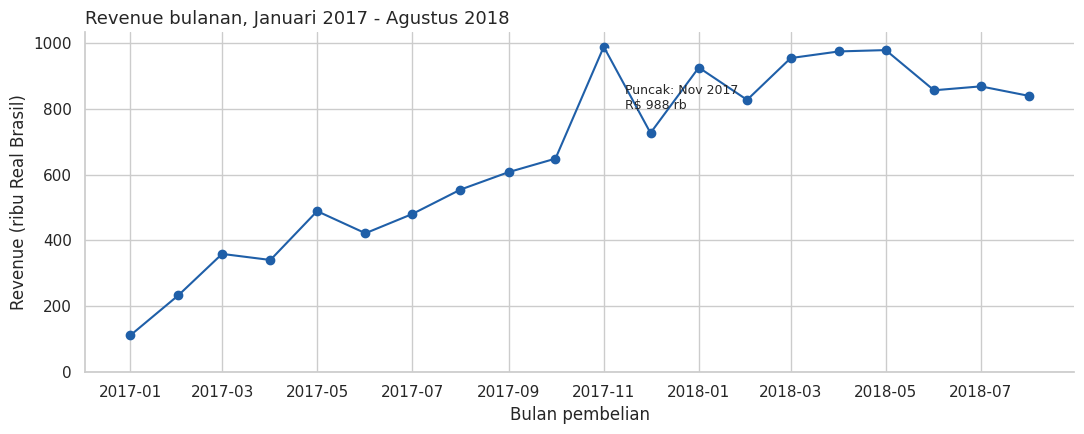

In [26]:
trend = monthly_revenue.copy()
trend.index = trend.index.to_timestamp()

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(trend.index, trend["revenue"] / 1e3, marker="o", color="#1f5fa8")
peak = trend["revenue"].idxmax()
ax.annotate(f"Puncak: {peak:%b %Y}\nR$ {trend['revenue'].max() / 1e3:,.0f} rb",
            (peak, trend["revenue"].max() / 1e3), xytext=(15, -45), textcoords="offset points",
            arrowprops=dict(arrowstyle="->"), fontsize=9)
ax.set_title("Revenue bulanan, Januari 2017 - Agustus 2018", fontsize=13, loc="left")
ax.set_xlabel("Bulan pembelian")
ax.set_ylabel("Revenue (ribu Real Brasil)")
ax.set_ylim(0, None)
sns.despine()
plt.tight_layout()
plt.show()

**Penjelasan grafik:** garis menunjukkan revenue bulanan. Revenue naik hampir sepanjang 2017 hingga puncak R$ 988 ribu pada November 2017, turun ke R$ 726 ribu pada Desember 2017 (penyebabnya tidak dapat dipastikan dari data ini), lalu mendatar di kisaran R$ 0,83 sampai 0,98 juta per bulan sepanjang 2018. Grafik ini memberi konteks bahwa total revenue periode analisis dibentuk oleh fase pertumbuhan 2017 dan fase stabil 2018.

### 5.2 Pertanyaan 1: Kategori produk apa saja yang masuk 10 besar berdasarkan total revenue, dan berapa persen kontribusinya terhadap total revenue pada periode Januari 2017 sampai Agustus 2018?

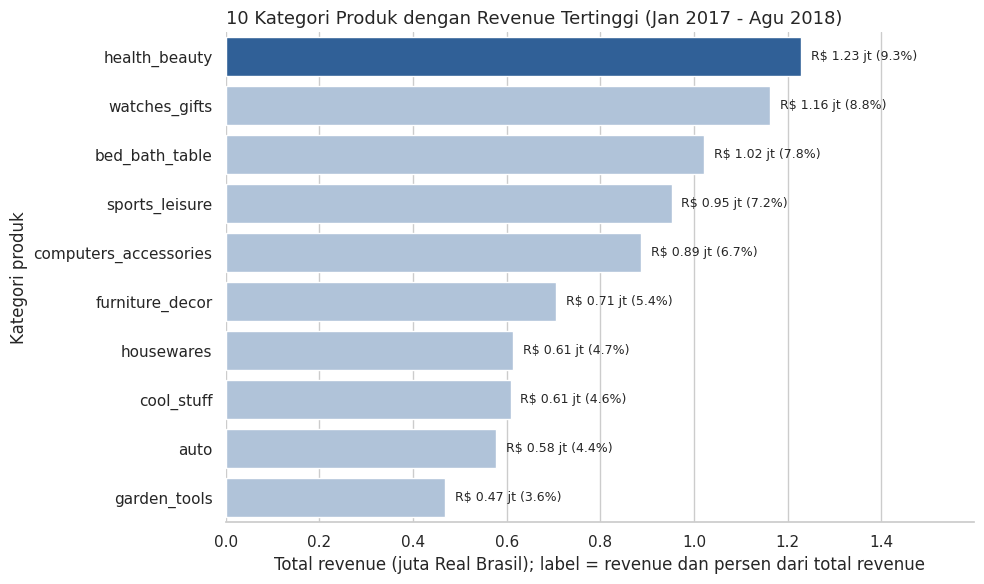

In [27]:
plot_cat = top10_cat.reset_index().copy()
plot_cat["revenue_m"] = plot_cat["revenue"] / 1e6
colors = ["#1f5fa8"] + ["#a9c3e0"] * 9   # sorot kategori teratas

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=plot_cat, x="revenue_m", y="product_category", hue="product_category", palette=colors, legend=False, ax=ax)
for i, row in plot_cat.iterrows():
    ax.text(row["revenue_m"] + 0.02, i, f"R$ {row['revenue_m']:.2f} jt ({row['share_pct']:.1f}%)", va="center", fontsize=9)
ax.set_title("10 Kategori Produk dengan Revenue Tertinggi (Jan 2017 - Agu 2018)", fontsize=13, loc="left")
ax.set_xlabel("Total revenue (juta Real Brasil); label = revenue dan persen dari total revenue")
ax.set_ylabel("Kategori produk")
ax.set_xlim(0, plot_cat["revenue_m"].max() * 1.3)
sns.despine(left=True)
plt.tight_layout()
plt.show()

**Penjelasan grafik:** batang horizontal menunjukkan revenue sepuluh kategori terbesar, dengan kategori teratas (`health_beauty`, R$ 1,23 juta atau 9,3%) disorot. Lima kategori pertama berada pada kisaran 9,3% sampai 6,7% (total 39,9%), lalu revenue menurun bertahap hingga `garden_tools` (R$ 0,47 juta; 3,6%). Sepuluh kategori ini bersama-sama menyumbang 62,5% revenue. Perlu diingat bahwa urutan teratas dipengaruhi barang bernilai tinggi: tanpa outlier harga, `bed_bath_table` menjadi peringkat 1 (lihat uji sensitivitas pada 4.2).

### 5.3 Pertanyaan 2: Bagaimana sebaran pelanggan ke dalam segmen RFM (Champions, Loyal, New High Value, Promising, At Risk, Lost) dan segmen mana yang menyumbang revenue terbesar pada periode Januari 2017 sampai Agustus 2018?

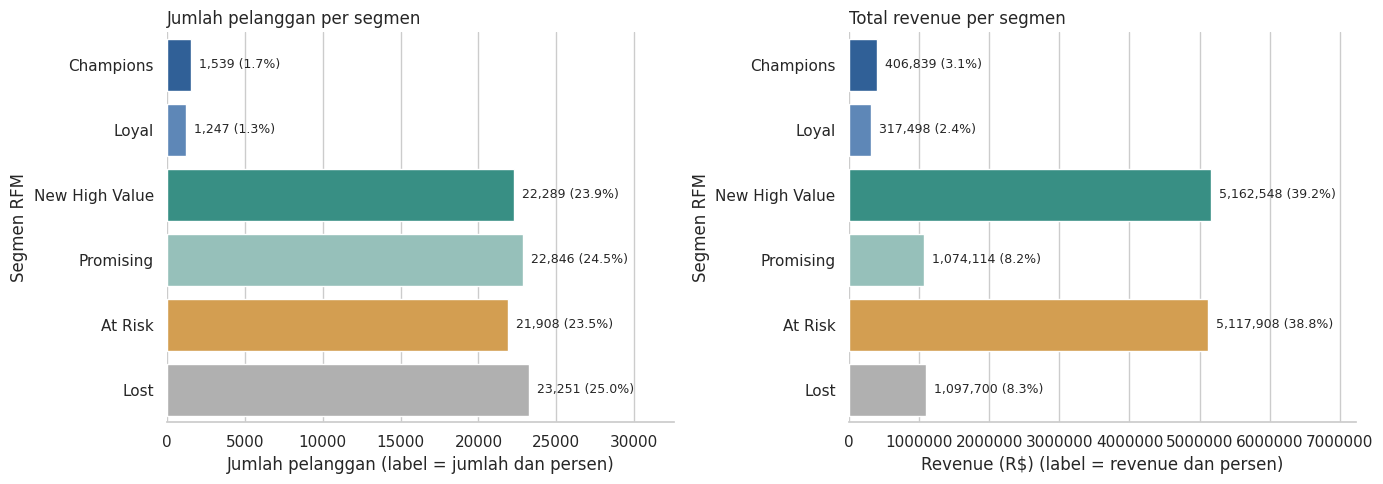

In [28]:
seg_colors = {"Champions": "#1f5fa8", "Loyal": "#4f86c6", "New High Value": "#2a9d8f",
              "Promising": "#8fc7bf", "At Risk": "#e9a23b", "Lost": "#b0b0b0"}
seg_plot = segment_summary.reset_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col, title, xlabel in [
    (axes[0], "customers", "Jumlah pelanggan per segmen", "Jumlah pelanggan (label = jumlah dan persen)"),
    (axes[1], "revenue", "Total revenue per segmen", "Revenue (R$) (label = revenue dan persen)"),
]:
    sns.barplot(data=seg_plot, x=col, y="segment", hue="segment", palette=seg_colors, legend=False, order=segment_order, ax=ax)
    pct_col = "customer_pct" if col == "customers" else "revenue_pct"
    for i, seg in enumerate(segment_order):
        val = seg_plot.loc[seg_plot["segment"] == seg, col].iloc[0]
        pct = seg_plot.loc[seg_plot["segment"] == seg, pct_col].iloc[0]
        ax.text(val, i, f"  {val:,.0f} ({pct:.1f}%)", va="center", fontsize=9)
    ax.set_title(title, fontsize=12, loc="left")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Segmen RFM")
    ax.set_xlim(0, seg_plot[col].max() * 1.4)
    ax.ticklabel_format(axis="x", style="plain")
sns.despine(left=True)
plt.tight_layout()
plt.show()

**Penjelasan grafik:** panel kiri menunjukkan jumlah pelanggan per segmen. Empat segmen pembeli satu kali berukuran hampir sama (23,5% sampai 25,0% pelanggan), sedangkan Champions (1,7%) dan Loyal (1,3%) sangat kecil. Panel kanan menunjukkan revenue per segmen: **New High Value** (R$ 5,16 juta; 39,2%) dan **At Risk** (R$ 5,12 juta; 38,8%) jauh melampaui segmen lain. Jadi perbedaan revenue antarsegmen terutama ditentukan oleh nilai belanja per pelanggan, bukan jumlah pelanggan.

### 5.4 Pertanyaan 3: Di negara bagian (state) mana pelanggan dan revenue paling terkonsentrasi, dan berapa rata-rata waktu pengiriman (hari) serta review score di setiap state pada periode Januari 2017 sampai Agustus 2018?

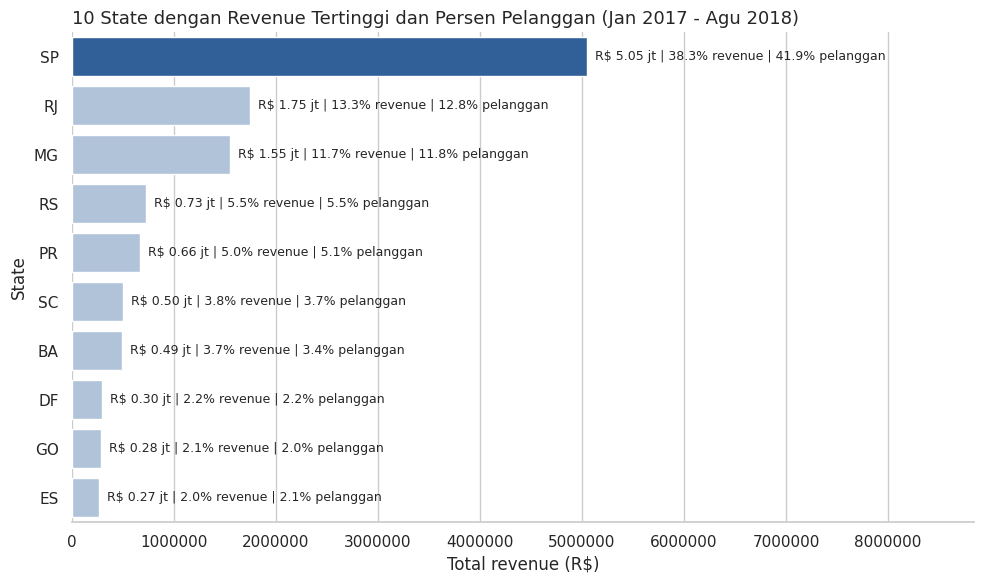

In [29]:
top_states = state_summary.head(10).copy()

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=top_states, x="revenue", y="customer_state", hue="customer_state",
            palette=["#1f5fa8"] + ["#a9c3e0"] * 9, legend=False, ax=ax)
for i, (_, r) in enumerate(top_states.iterrows()):
    ax.text(r["revenue"], i, f"  R$ {r['revenue'] / 1e6:.2f} jt | {r['revenue_pct']:.1f}% revenue | {r['customers_pct']:.1f}% pelanggan",
            va="center", fontsize=9)
ax.set_title("10 State dengan Revenue Tertinggi dan Persen Pelanggan (Jan 2017 - Agu 2018)", fontsize=13, loc="left")
ax.set_xlabel("Total revenue (R$)")
ax.set_ylabel("State")
ax.set_xlim(0, top_states["revenue"].max() * 1.75)
ax.ticklabel_format(axis="x", style="plain")
sns.despine(left=True)
plt.tight_layout()
plt.show()

**Penjelasan grafik:** SP jauh terpisah dari state lain, dengan revenue R$ 5,05 juta (38,3% revenue) dan 41,9% pelanggan. RJ (13,3% revenue; 12,8% pelanggan) dan MG (11,7%; 11,8%) berada di posisi 2 dan 3. Setelah tiga state teratas, kontribusi tiap state turun menjadi 5,5% atau kurang, sehingga pelanggan dan revenue sangat terkonsentrasi di Tenggara dan Selatan Brasil.

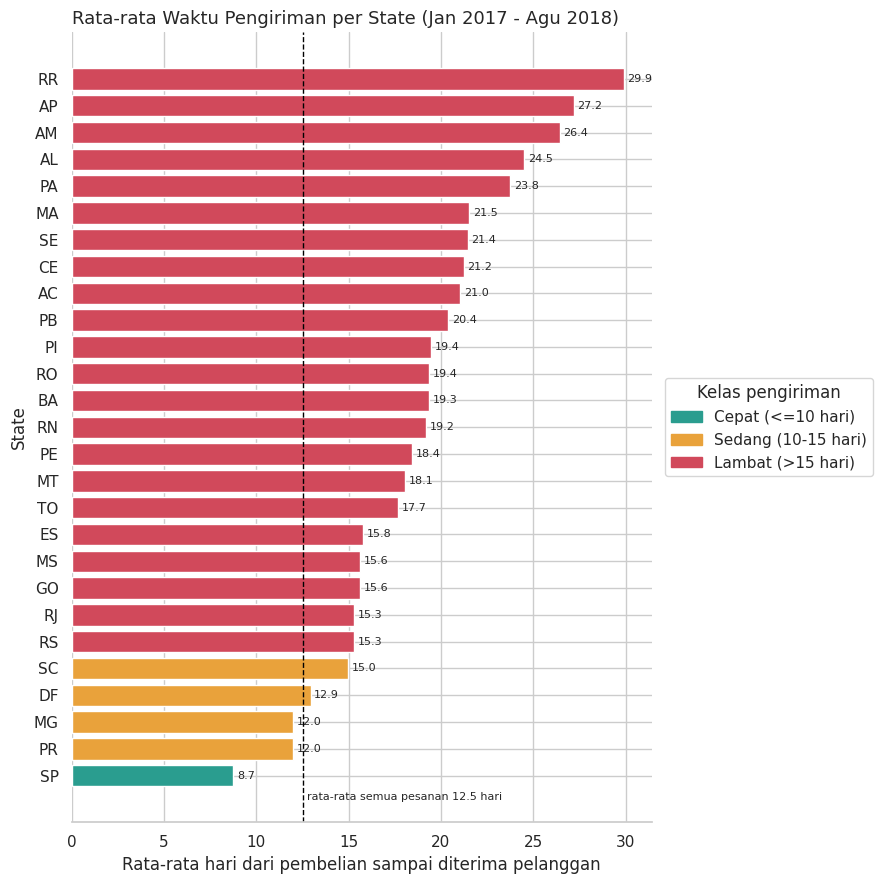

In [30]:
class_colors = {"Cepat (<=10 hari)": "#2a9d8f", "Sedang (10-15 hari)": "#e9a23b", "Lambat (>15 hari)": "#d1495b"}
d = state_summary.sort_values("avg_delivery_days")

fig, ax = plt.subplots(figsize=(9, 9))
ax.barh(d["customer_state"], d["avg_delivery_days"], color=d["delivery_class"].astype(str).map(class_colors))
for y, v in enumerate(d["avg_delivery_days"]):
    ax.text(v + 0.2, y, f"{v:.1f}", va="center", fontsize=8)
ax.axvline(overall_delivery, color="black", linestyle="--", linewidth=1)
ax.text(overall_delivery + 0.2, -0.9, f"rata-rata semua pesanan {overall_delivery:.1f} hari", fontsize=8)
ax.set_title("Rata-rata Waktu Pengiriman per State (Jan 2017 - Agu 2018)", fontsize=13, loc="left")
ax.set_xlabel("Rata-rata hari dari pembelian sampai diterima pelanggan")
ax.set_ylabel("State")
ax.legend(handles=[Patch(color=c, label=l) for l, c in class_colors.items()], title="Kelas pengiriman", loc="center left", bbox_to_anchor=(1.01, 0.5))
sns.despine(left=True)
plt.tight_layout()
plt.show()

**Penjelasan grafik:** setiap batang adalah rata-rata waktu pengiriman satu state, dengan garis putus-putus menandai rata-rata seluruh pesanan (12,5 hari). SP adalah satu-satunya state hijau (8,7 hari). SC, DF, MG, dan PR berwarna kuning (12,0 sampai 15,0 hari). RJ dan RS (masing-masing 15,3 hari) baru sedikit melewati batas 15 hari, sedangkan BA mencapai 19,3 hari. Lima state terlambat berada di wilayah utara dan timur laut: RR (29,9), AP (27,2), AM (26,4), AL (24,5), dan PA (23,8 hari).

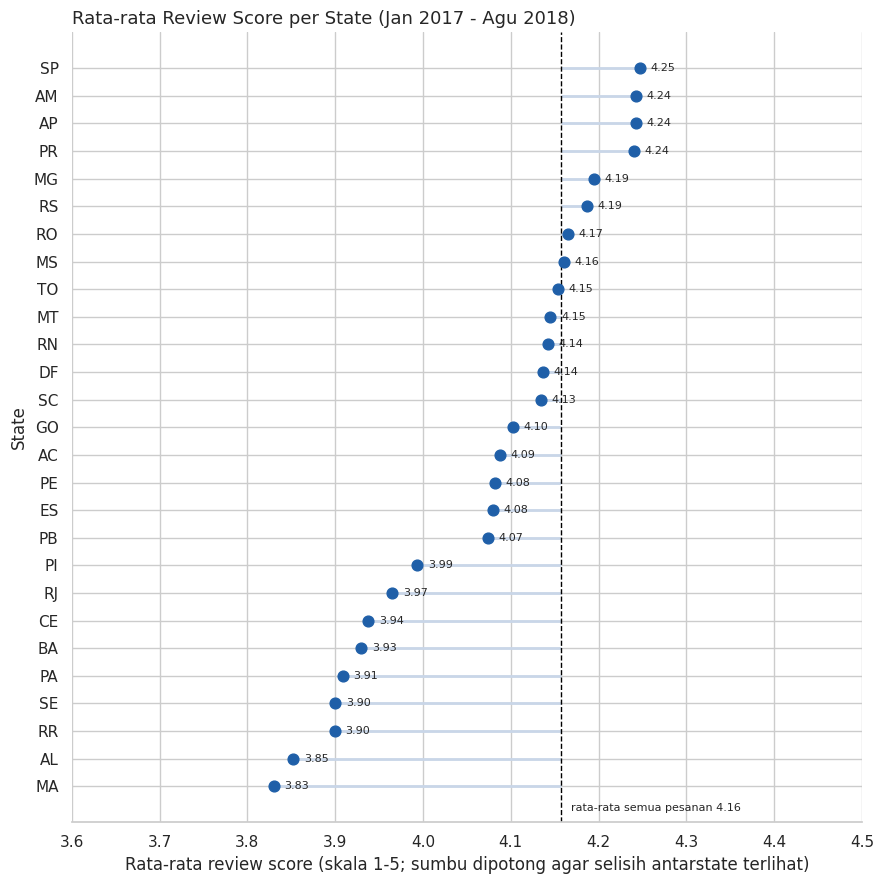

In [31]:
r = state_summary.sort_values("avg_review_score")

fig, ax = plt.subplots(figsize=(9, 9))
ax.hlines(r["customer_state"], overall_review, r["avg_review_score"], color="#c9d6e8", linewidth=2)
ax.scatter(r["avg_review_score"], r["customer_state"], s=60, color="#1f5fa8", zorder=3)
for y, v in enumerate(r["avg_review_score"]):
    ax.text(v + 0.012, y, f"{v:.2f}", va="center", fontsize=8)
ax.axvline(overall_review, color="black", linestyle="--", linewidth=1)
ax.text(overall_review + 0.012, -0.9, f"rata-rata semua pesanan {overall_review:.2f}", fontsize=8)
ax.set_title("Rata-rata Review Score per State (Jan 2017 - Agu 2018)", fontsize=13, loc="left")
ax.set_xlabel("Rata-rata review score (skala 1-5; sumbu dipotong agar selisih antarstate terlihat)")
ax.set_ylabel("State")
ax.set_xlim(3.6, 4.5)
sns.despine(left=True)
plt.tight_layout()
plt.show()

**Penjelasan grafik:** titik menunjukkan rata-rata review tiap state terhadap rata-rata seluruh pesanan (4,16; garis putus-putus). Sumbu sengaja dipotong pada 3,6 sampai 4,5 agar selisih antarstate terlihat, jadi selisihnya perlu dibaca dari label angka: seluruh state berada pada rentang 3,83 (MA) sampai 4,25 (SP). State di bawah rata-rata termasuk dua state besar, RJ (3,97) dan BA (3,93), serta CE (3,94) dan PA (3,91). Secara umum state dengan pengiriman lebih lambat cenderung berulasan lebih rendah (misalnya MA 3,83 pada 21,5 hari dan AL 3,85 pada 24,5 hari). Pengecualiannya AP dan AM (4,24), yang jumlah pesanannya kecil (67 dan 145).

#### Analisis geospatial: peta persebaran revenue dan waktu pengiriman

Ukuran lingkaran menunjukkan revenue dan warna menunjukkan rata-rata waktu pengiriman. Koordinat setiap state memakai titik tengah (median) dari data `geolocation` yang sudah dibersihkan.

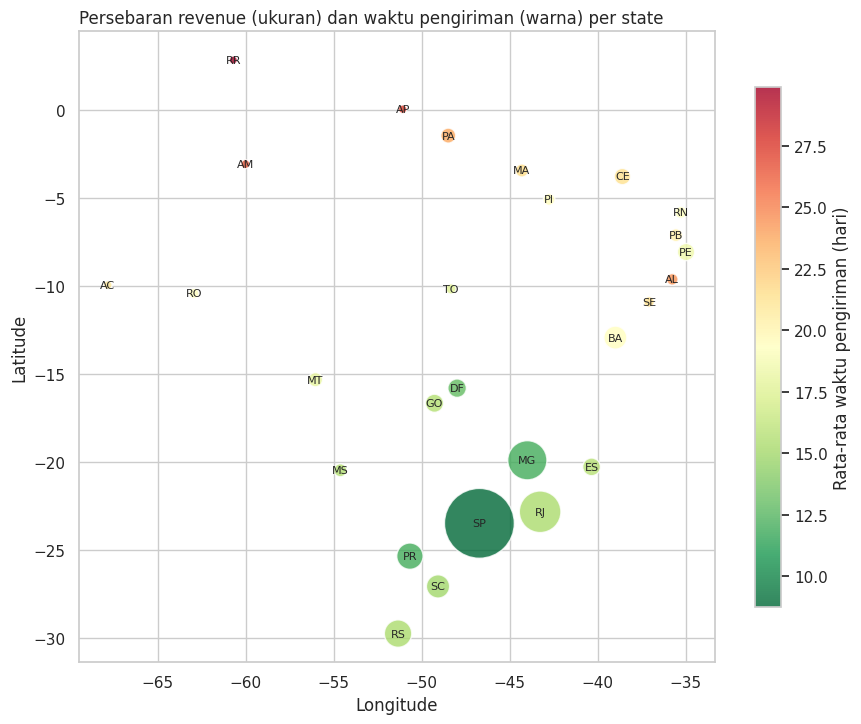

In [32]:
geo_plot = state_summary.dropna(subset=["latitude", "longitude"])

fig, ax = plt.subplots(figsize=(9, 8))
sc = ax.scatter(geo_plot["longitude"], geo_plot["latitude"],
                s=geo_plot["revenue"] / geo_plot["revenue"].max() * 2500 + 30,
                c=geo_plot["avg_delivery_days"], cmap="RdYlGn_r", alpha=0.8, edgecolor="white", linewidth=1)
for _, r in geo_plot.iterrows():
    ax.annotate(r["customer_state"], (r["longitude"], r["latitude"]), ha="center", va="center", fontsize=8)
cb = plt.colorbar(sc, ax=ax, shrink=0.7)
cb.set_label("Rata-rata waktu pengiriman (hari)")
ax.set_title("Persebaran revenue (ukuran) dan waktu pengiriman (warna) per state", fontsize=12, loc="left")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

In [33]:
# Peta interaktif (opsional): membutuhkan folium -> pip install folium
try:
    import folium

    peta = folium.Map(location=[-14.2, -51.9], zoom_start=4, tiles="CartoDB positron")
    max_rev = geo_plot["revenue"].max()
    for _, r in geo_plot.iterrows():
        folium.CircleMarker(
            location=[r["latitude"], r["longitude"]],
            radius=max(5, (r["revenue"] / max_rev) ** 0.5 * 35),
            color="#1f5fa8", fill=True, fill_opacity=0.5,
            popup=folium.Popup(f"<b>{r['customer_state']}</b><br>Revenue: R$ {r['revenue']:,.0f}"
                               f"<br>Pelanggan: {r['customers']:,}<br>Waktu kirim: {r['avg_delivery_days']:.1f} hari"
                               f"<br>Review: {r['avg_review_score']:.2f}", max_width=250),
        ).add_to(peta)
    peta.save("peta_revenue_state.html")
    peta
except ImportError:
    print("folium belum terpasang. Jalankan: pip install folium")

/usr/local/lib/python3.13/dist-packages/folium/raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


**Penjelasan peta:** lingkaran terbesar dan paling hijau adalah SP, diikuti RJ, MG, RS, PR, dan SC di tenggara dan selatan dengan revenue sedang dan waktu pengiriman lebih pendek. Wilayah utara dan timur laut tampil sebagai lingkaran kecil berwarna oranye sampai merah (RR, AP, AM, PA, AL): revenue-nya kecil dan waktu pengirimannya paling lama. Pola ini menunjukkan permintaan terkonsentrasi di dekat pusat distribusi, sedangkan wilayah jauh dilayani dengan lebih lambat.

#### Hubungan waktu pengiriman dan kepuasan pelanggan

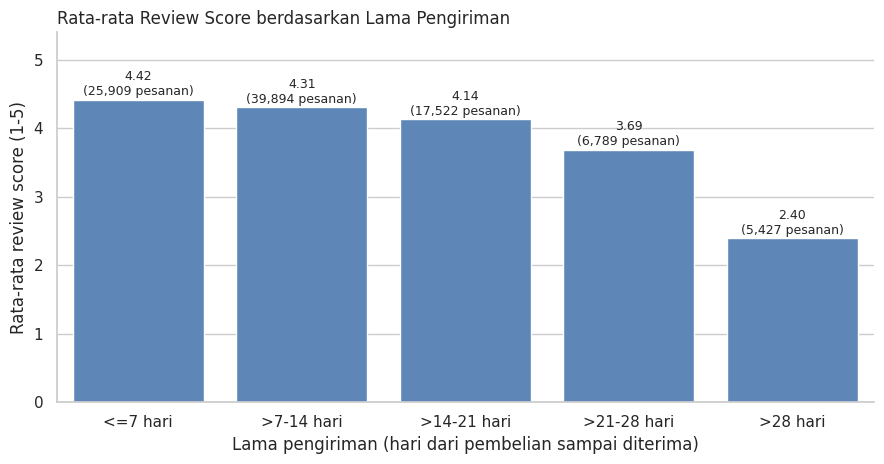

In [34]:
fig, ax = plt.subplots(figsize=(9, 4.8))
dvr = delivery_vs_review.reset_index()
sns.barplot(data=dvr, x="delivery_bin", y="avg_review", color="#4f86c6", ax=ax)
for i, row in dvr.iterrows():
    ax.text(i, row["avg_review"] + 0.06, f"{row['avg_review']:.2f}\n({row['orders']:,} pesanan)", ha="center", fontsize=9)
ax.set_title("Rata-rata Review Score berdasarkan Lama Pengiriman", fontsize=12, loc="left")
ax.set_xlabel("Lama pengiriman (hari dari pembelian sampai diterima)")
ax.set_ylabel("Rata-rata review score (1-5)")
ax.set_ylim(0, 5.4)
sns.despine()
plt.tight_layout()
plt.show()

**Penjelasan grafik:** rata-rata review menurun seiring lama pengiriman: 4,42 (7 hari atau kurang; 25.909 pesanan), 4,31 (>7 sampai 14 hari; 39.894), 4,14 (>14 sampai 21 hari; 17.522), 3,69 (>21 sampai 28 hari; 6.789), dan 2,40 (lebih dari 28 hari; 5.427). Penurunan paling tajam terjadi setelah 21 hari. Sebanyak 31,1% pesanan berulasan membutuhkan lebih dari 14 hari. Catatan: ini hubungan (korelasi -0,33), belum membuktikan bahwa keterlambatan adalah satu-satunya penyebab review rendah.

## 6. Conclusion & Recommendation

### Kesimpulan Pertanyaan 1
**Kategori produk apa saja yang masuk 10 besar berdasarkan total revenue, dan berapa persen kontribusinya terhadap total revenue pada periode Januari 2017 sampai Agustus 2018?**

Sepuluh kategori teratas menyumbang **62,5%** dari total revenue R$ 13.176.606. Urutan dan kontribusinya:

| Peringkat | Kategori | Revenue (R$) | Kontribusi (%) |
|---|---|---|---|
| 1 | health_beauty | 1.229.426 | 9,33 |
| 2 | watches_gifts | 1.163.121 | 8,83 |
| 3 | bed_bath_table | 1.022.541 | 7,76 |
| 4 | sports_leisure | 952.476 | 7,23 |
| 5 | computers_accessories | 887.762 | 6,74 |
| 6 | furniture_decor | 705.756 | 5,36 |
| 7 | housewares | 614.143 | 4,66 |
| 8 | cool_stuff | 609.070 | 4,62 |
| 9 | auto | 577.695 | 4,38 |
| 10 | garden_tools | 468.853 | 3,56 |

Revenue tidak selalu mengikuti jumlah pesanan: `bed_bath_table` memiliki pesanan terbanyak (9.264) tetapi hanya R$ 110,38 per pesanan, sedangkan `watches_gifts` mencapai R$ 211,94 per pesanan. Hasil ini juga sensitif terhadap barang bernilai tinggi: tanpa outlier harga, `bed_bath_table` menjadi peringkat 1, tetapi sembilan dari sepuluh kategori tetap berada di 10 besar.

### Kesimpulan Pertanyaan 2
**Bagaimana sebaran pelanggan ke dalam segmen RFM (Champions, Loyal, New High Value, Promising, At Risk, Lost) dan segmen mana yang menyumbang revenue terbesar pada periode Januari 2017 sampai Agustus 2018?**

Hanya 3,0% pelanggan (2.786 dari 93.080) yang membeli lebih dari sekali. Sebaran pelanggan dan revenue per segmen:

| Segmen | Pelanggan | Pelanggan (%) | Revenue (R$) | Revenue (%) |
|---|---|---|---|---|
| Champions | 1.539 | 1,65 | 406.839 | 3,09 |
| Loyal | 1.247 | 1,34 | 317.498 | 2,41 |
| New High Value | 22.289 | 23,95 | 5.162.548 | 39,18 |
| Promising | 22.846 | 24,54 | 1.074.114 | 8,15 |
| At Risk | 21.908 | 23,54 | 5.117.908 | 38,84 |
| Lost | 23.251 | 24,98 | 1.097.700 | 8,33 |

Segmen yang menyumbang revenue terbesar adalah **New High Value** (39,18%), disusul **At Risk** (38,84%). Keduanya bernilai belanja tinggi (sekitar R$ 232 sampai 234 per pelanggan), tetapi pelanggan At Risk sudah rata-rata 362 hari tidak membeli. Dengan kata lain, hampir 39% revenue bergantung pada pelanggan yang sudah lama tidak kembali.

### Kesimpulan Pertanyaan 3
**Di negara bagian (state) mana pelanggan dan revenue paling terkonsentrasi, dan berapa rata-rata waktu pengiriman (hari) serta review score di setiap state pada periode Januari 2017 sampai Agustus 2018?**

Pelanggan dan revenue paling terkonsentrasi di **SP** (41,93% pelanggan; 38,35% revenue), dan tiga state teratas (SP, RJ, MG) menyumbang 63,4% revenue. Rata-rata waktu pengiriman dan review score setiap state:

| State | Pelanggan (%) | Revenue (%) | Pesanan | Rata-rata hari kirim | Rata-rata review | Kelas pengiriman |
|---|---|---|---|---|---|---|
| SP | 41,93 | 38,35 | 40.387 | 8,74 | 4,25 | Cepat (<=10 hari) |
| RJ | 12,76 | 13,29 | 12.310 | 15,30 | 3,97 | Lambat (>15 hari) |
| MG | 11,78 | 11,74 | 11.315 | 11,99 | 4,19 | Sedang (10-15 hari) |
| RS | 5,53 | 5,51 | 5.326 | 15,29 | 4,19 | Lambat (>15 hari) |
| PR | 5,10 | 5,04 | 4.903 | 11,97 | 4,24 | Sedang (10-15 hari) |
| SC | 3,69 | 3,83 | 3.535 | 14,95 | 4,13 | Sedang (10-15 hari) |
| BA | 3,39 | 3,74 | 3.253 | 19,33 | 3,93 | Lambat (>15 hari) |
| DF | 2,16 | 2,24 | 2.074 | 12,94 | 4,14 | Sedang (10-15 hari) |
| GO | 2,03 | 2,14 | 1.950 | 15,61 | 4,10 | Lambat (>15 hari) |
| ES | 2,07 | 2,03 | 1.992 | 15,78 | 4,08 | Lambat (>15 hari) |
| PE | 1,66 | 1,90 | 1.587 | 18,45 | 4,08 | Lambat (>15 hari) |
| CE | 1,34 | 1,66 | 1.273 | 21,24 | 3,94 | Lambat (>15 hari) |
| PA | 0,99 | 1,32 | 942 | 23,76 | 3,91 | Lambat (>15 hari) |
| MT | 0,92 | 1,15 | 885 | 18,07 | 4,15 | Lambat (>15 hari) |
| MA | 0,75 | 0,88 | 713 | 21,54 | 3,83 | Lambat (>15 hari) |
| MS | 0,73 | 0,88 | 701 | 15,62 | 4,16 | Lambat (>15 hari) |
| PB | 0,54 | 0,85 | 516 | 20,39 | 4,07 | Lambat (>15 hari) |
| PI | 0,50 | 0,64 | 475 | 19,44 | 3,99 | Lambat (>15 hari) |
| RN | 0,49 | 0,62 | 470 | 19,21 | 4,14 | Lambat (>15 hari) |
| AL | 0,41 | 0,60 | 396 | 24,52 | 3,85 | Lambat (>15 hari) |
| SE | 0,35 | 0,43 | 332 | 21,44 | 3,90 | Lambat (>15 hari) |
| TO | 0,29 | 0,37 | 274 | 17,66 | 4,15 | Lambat (>15 hari) |
| RO | 0,25 | 0,35 | 243 | 19,37 | 4,17 | Lambat (>15 hari) |
| AM | 0,15 | 0,17 | 145 | 26,43 | 4,24 | Lambat (>15 hari) |
| AC | 0,08 | 0,12 | 80 | 21,04 | 4,09 | Lambat (>15 hari) |
| AP | 0,07 | 0,10 | 67 | 27,19 | 4,24 | Lambat (>15 hari) |
| RR | 0,04 | 0,05 | 40 | 29,91 | 3,90 | Lambat (>15 hari) |

Rata-rata seluruh pesanan adalah 12,54 hari dan review 4,16. Hanya SP yang masuk kelas pengiriman Cepat (8,74 hari), sedangkan 22 dari 27 state Lambat (di atas 15 hari). Review terendah ada di MA (3,83), AL (3,85), RR dan SE (3,90), serta PA (3,91). Dua state besar, RJ (3,97) dan BA (3,93), juga di bawah rata-rata. Lama pengiriman berkaitan dengan kepuasan: review turun dari 4,42 (7 hari atau kurang) menjadi 2,40 (lebih dari 28 hari), dan 31,1% pesanan berulasan memerlukan lebih dari 14 hari. Catatan: ini korelasi (-0,33), bukan bukti sebab-akibat, dan rata-rata state kecil (RR 40 pesanan, AP 67, AM 145) kurang stabil.

### Rekomendasi (Action Item)

1. **Fokuskan stok, promosi, dan seller pada kategori yang stabil di 10 besar.** Prioritaskan `bed_bath_table`, `sports_leisure`, `computers_accessories`, dan `furniture_decor` yang tetap kuat meski outlier harga dikeluarkan, serta `health_beauty` dan `watches_gifts` yang kuat karena barang bernilai tinggi (jaga ketersediaan seller untuk barang premium). Untuk `bed_bath_table` yang volumenya besar tetapi nilai per pesanan hanya R$ 110,38, buat paket bundling untuk menaikkan nilai keranjang.
2. **Jalankan program retensi berdasarkan segmen RFM.** Untuk **At Risk** (21.908 pelanggan; R$ 5,12 juta), kirim kampanye win-back berupa voucher atau email pengingat. Untuk **New High Value** (22.289 pelanggan; R$ 5,16 juta), tawarkan produk pelengkap atau voucher agar terjadi pembelian kedua dan mereka berkembang menjadi Champions. Berikan program loyalitas sederhana untuk Champions dan Loyal. Untuk Promising dan Lost (belanja sekitar R$ 47), cukup komunikasi otomatis berbiaya rendah.
3. **Tekan pengiriman lambat di state berpesanan besar.** Prioritaskan **RJ** (12.310 pesanan; 15,30 hari; review 3,97) dan **BA** (3.253 pesanan; 19,33 hari; review 3,93), serta CE dan PE (21,24 dan 18,45 hari), melalui seller atau gudang yang lebih dekat dan evaluasi mitra kurir. Pantau pesanan yang melebihi 21 hari (12.216 pesanan, 12,8% pesanan berulasan) karena review jatuh tajam di atas batas itu (3,69 dan 2,40). Untuk state utara dengan volume kecil, tampilkan estimasi pengiriman yang realistis agar ekspektasi pelanggan terkelola.